# Praktikum 3 — Eksplorasi Visual dan Dekomposisi Deret Waktu: Klasik, STL, dan Kekuatan Komponen

---

Nama: Safina Zahra  
NIM: 52250033  
Mata kuliah: Analisis Runtun Waktu  
Program studi: Sains Data, Institut Teknologi Sains Bandung  
Dosen pengampu: Bakti Siregar, S.Si., M.Sc  
Materi: Bab 3 — Eksplorasi dan Dekomposisi (Latihan 3.1, 3.2, 3.3)

---


## Gambaran umum

**Tujuan.** Praktikum ini melatih cara memisahkan sebuah deret waktu menjadi tren, musiman, dan residu: (1) membaca pola lewat seasonal plot, boxplot per bulan, dan heatmap; (2) melakukan dekomposisi klasik yang ditulis dari nol dan dekomposisi STL; (3) memilih model aditif atau multiplikatif dari data dan residunya; (4) mengukur kekuatan tren dan musiman dengan F_T dan F_S; (5) memahami apa yang terjadi bila periode musiman salah ditentukan.

**Alur kerja.**
1. Membuat fungsi `dekomposisi_klasik` dan `kekuatan`, lalu memverifikasinya dengan statsmodels.
2. Latihan 3.1: eksplorasi dan dekomposisi data Tugas 1, yaitu inflasi bulanan Indonesia (BPS).
3. Latihan 3.2: dekomposisi suhu harian Melbourne dengan m = 365 dan perbandingan dengan STL.
4. Latihan 3.3: dekomposisi Airline dengan period = 6, 12, dan 24.

Setiap bagian diakhiri kotak *Interpretasi* yang menjelaskan arti angka dan grafik.


## 0. Persiapan

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose, STL

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'figure.figsize': (10, 3.4)})
BRN = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/'

In [ ]:
# Data Tugas 1: inflasi bulanan Indonesia (berkas yang sama dengan Praktikum 1 dan 2)
FILE = 'tingkat-inflasi-bulan-ke-bulan-gabungan-90-kota-seluruh-indonesia.csv'
if not os.path.exists(FILE):                     # di Colab: unggah berkas CSV-nya dulu
    from google.colab import files
    files.upload()

mentah = pd.read_csv(FILE, sep=';')
nama_bulan = {'Januari': 1, 'Februari': 2, 'Maret': 3, 'April': 4, 'Mei': 5, 'Juni': 6,
              'Juli': 7, 'Agustus': 8, 'September': 9, 'Oktober': 10, 'November': 11, 'Desember': 12}
tgl = pd.to_datetime(dict(year=mentah['tahun'], month=mentah['bulan'].map(nama_bulan), day=1))
inflasi = pd.Series(mentah['tingkat_inflasi_bulanan'].values, index=pd.DatetimeIndex(tgl, freq='MS'),
                    name='inflasi_bulanan_persen')

# Data untuk Latihan 3.2 dan 3.3
air = pd.read_csv(BRN + 'airline-passengers.csv', parse_dates=['Month'], index_col='Month')['Passengers'].asfreq('MS')
suhu_mentah = pd.read_csv(BRN + 'daily-min-temperatures.csv', parse_dates=['Date'], index_col='Date')['Temp']
suhu = suhu_mentah.asfreq('D').interpolate()          # tanggal yang hilang diisi interpolasi
print('inflasi:', len(inflasi), '| airline:', len(air), '| suhu harian:', len(suhu))

inflasi: 231 | airline: 144 | suhu harian: 3652


## 1. Alat: dekomposisi klasik yang ditulis dari nol
Algoritmanya: (1) tren dengan rata-rata bergerak terpusat, (2) buang tren dari data, (3) indeks musiman = rata-rata per posisi dalam periode lalu dinormalkan, (4) residu = sisanya. Versi multiplikatif memakai pembagian, sehingga data harus positif.

In [ ]:
def dekomposisi_klasik(y, m=12, model='additive'):
    """Dekomposisi klasik dari nol. Kembalikan DataFrame: y, tren, musiman, residu."""
    if model not in ('additive', 'multiplicative'):
        raise ValueError("model harus 'additive' atau 'multiplicative'")
    if len(y) < 2 * m:
        raise ValueError(f'perlu minimal 2 periode penuh ({2 * m} pengamatan)')
    if model == 'multiplicative' and (y <= 0).any():
        raise ValueError(f'model multiplikatif butuh data positif, ada {(y <= 0).sum()} nilai <= 0')
    # 1) tren: rata-rata bergerak terpusat (m genap -> 2 x m-MA)
    if m % 2 == 0:
        tren = y.rolling(m).mean().rolling(2).mean().shift(-m // 2)
    else:
        tren = y.rolling(m, center=True).mean()
    # 2) data tanpa tren
    lepas = y - tren if model == 'additive' else y / tren
    # 3) indeks musiman per posisi dalam periode
    posisi = np.arange(len(y)) % m
    indeks = lepas.groupby(posisi).mean()
    indeks = indeks - indeks.mean() if model == 'additive' else indeks / indeks.mean()
    musiman = pd.Series(indeks.values[posisi], index=y.index)
    # 4) residu
    residu = y - tren - musiman if model == 'additive' else y / (tren * musiman)
    return pd.DataFrame({'y': y, 'tren': tren, 'musiman': musiman, 'residu': residu})

def kekuatan(res):
    """Kekuatan tren (F_T) dan musiman (F_S) menurut Wang dkk. (2006); mendekati 1 = kuat."""
    T, S, R = res.trend, res.seasonal, res.resid
    return {'F_tren': max(0, 1 - R.var() / (T + R).var()), 'F_musiman': max(0, 1 - R.var() / (S + R).var())}

# Uji kebenaran: bandingkan dengan statsmodels pada Airline (multiplikatif)
kita = dekomposisi_klasik(air, model='multiplicative')
sm_dec = seasonal_decompose(air, model='multiplicative', period=12)
print('selisih maksimum dengan statsmodels, tren   :', np.nanmax(np.abs(kita.tren - sm_dec.trend)).round(10))
print('selisih maksimum dengan statsmodels, musiman:', np.nanmax(np.abs(kita.musiman - sm_dec.seasonal)).round(10))

selisih maksimum dengan statsmodels, tren   : 0.0
selisih maksimum dengan statsmodels, musiman: 0.0


> **Interpretasi.** Selisih maksimum dengan `seasonal_decompose` statsmodels adalah 0,0 untuk tren maupun musiman, jadi implementasi dari nol ini benar. Fungsinya juga menolak data dengan nilai ≤ 0 pada model multiplikatif (karena membagi dengan tren dan indeks musiman), dan menolak deret yang kurang dari dua periode penuh.


## 2. Latihan 3.1 — Eksplorasi dan dekomposisi data Tugas 1 (inflasi bulanan)

### 2.1 Seasonal plot, boxplot per bulan, dan heatmap

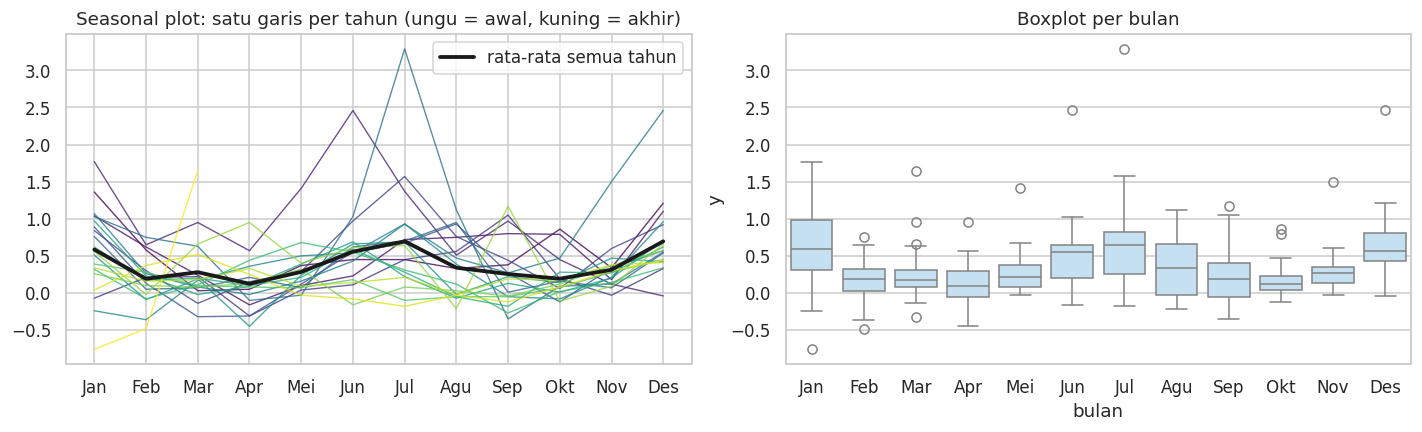

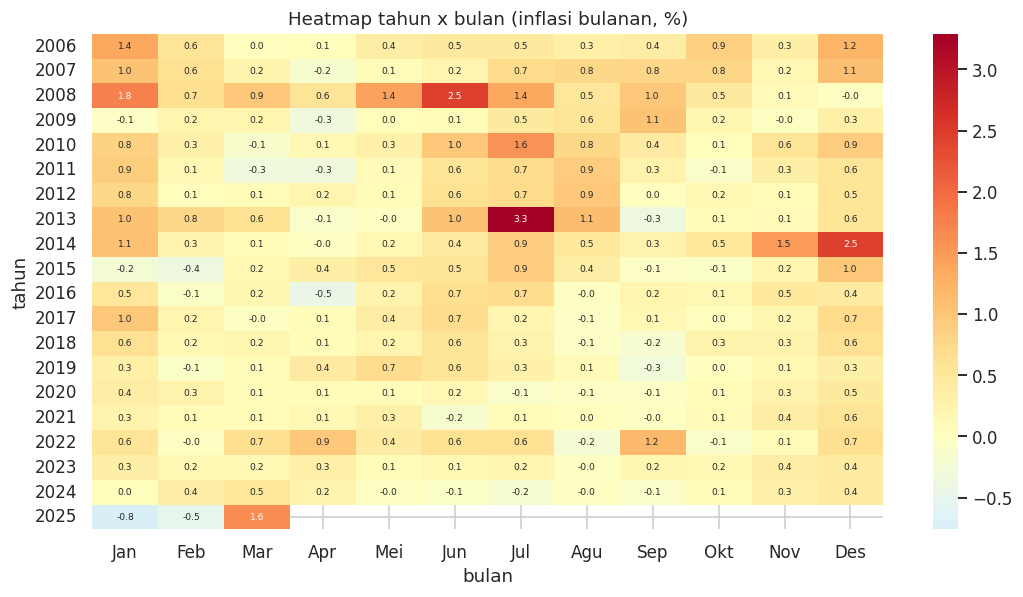

         Jan   Feb   Mar   Apr   Mei   Jun   Jul   Agu   Sep   Okt   Nov   Des
mean    0.59  0.19  0.28  0.12  0.28  0.56  0.70  0.34  0.25  0.19  0.31  0.70
median  0.59  0.19  0.18  0.10  0.21  0.55  0.64  0.33  0.19  0.12  0.27  0.57
std     0.58  0.32  0.43  0.33  0.33  0.56  0.77  0.41  0.45  0.27  0.32  0.52


In [ ]:
df = pd.DataFrame({'y': inflasi, 'tahun': inflasi.index.year, 'bulan': inflasi.index.month})
nama_pendek = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for th, g in df.groupby('tahun'):
    ax[0].plot(g.bulan, g.y, color=plt.cm.viridis((th - 2006) / 19), lw=.9, alpha=.8)
ax[0].plot(range(1, 13), df.groupby('bulan').y.mean(), color='k', lw=2.5, label='rata-rata semua tahun')
ax[0].set_xticks(range(1, 13)); ax[0].set_xticklabels(nama_pendek); ax[0].legend()
ax[0].set_title('Seasonal plot: satu garis per tahun (ungu = awal, kuning = akhir)')
sns.boxplot(data=df, x='bulan', y='y', ax=ax[1], color='#bee3f8')
ax[1].set_xticklabels(nama_pendek); ax[1].set_title('Boxplot per bulan')
plt.tight_layout(); plt.show()

piv = df.pivot(index='tahun', columns='bulan', values='y')
plt.figure(figsize=(10, 5.5))
sns.heatmap(piv, cmap='RdYlBu_r', center=0, annot=True, fmt='.1f', annot_kws={'size': 6}, cbar=True,
            xticklabels=nama_pendek)
plt.title('Heatmap tahun x bulan (inflasi bulanan, %)'); plt.tight_layout(); plt.show()

rata_bulan = df.groupby('bulan').y.agg(['mean', 'median', 'std']).round(2)
rata_bulan.index = nama_pendek
print(rata_bulan.T)

> **Interpretasi.**
> - **Seasonal plot:** garis tiap tahun tidak sejajar rapi seperti pada Airline. Pola yang berulang hanya samar: Januari, Juni–Juli, dan Desember cenderung lebih tinggi. Garis tahun-tahun awal (ungu) banyak melonjak jauh di atas rata-rata, sedangkan tahun-tahun akhir (kuning) mengumpul dekat nol.
> - **Boxplot dan rata-rata per bulan:** bulan tertinggi Juli dan Desember (rata-rata 0,70%), disusul Januari (0,59%) dan Juni (0,56%); terendah April (0,12%). Simpangan baku terbesar ada di Juli (0,77) karena memuat lonjakan Juli 2013 (3,29%).
> - **Heatmap:** sel paling gelap adalah Juli 2013 (3,3), Juni 2008 (2,5), dan Desember 2014 (2,5), yaitu kejutan harga, bukan pola musiman. Warna tahun 2018–2024 jauh lebih pucat, tanda level inflasi turun. Awal 2025 memperlihatkan Januari −0,8 dan Februari −0,5, lalu Maret 1,6.
>
> Kesan awalnya: ada musiman ringan (akhir dan pertengahan tahun naik), tetapi tertutup derau dan beberapa lonjakan besar.


### 2.2 Dekomposisi klasik dan pemilihan aditif / multiplikatif

nilai <= 0 pada inflasi : 42 dari 231
Multiplikatif ditolak  : model multiplikatif butuh data positif, ada 42 nilai <= 0


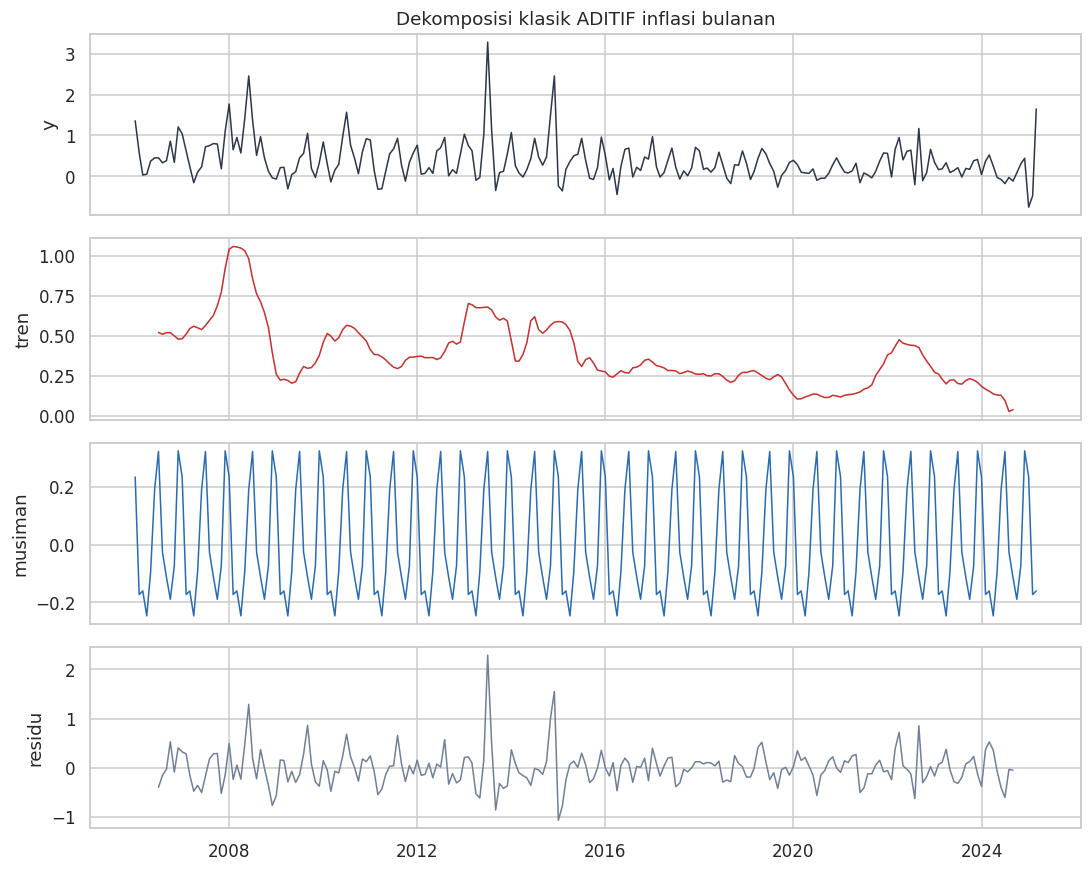


indeks musiman aditif (persen poin):
          Jan    Feb   Mar    Apr    Mei    Jun    Jul    Agu    Sep    Okt  \
indeks  0.235 -0.173 -0.16 -0.247 -0.094  0.191  0.323 -0.026 -0.113 -0.189   

          Nov    Des  
indeks -0.073  0.325  

rentang indeks musiman  : 0.572
std residu aditif       : 0.371
rasio std residu paruh 2 / paruh 1 : 0.57
autokorelasi residu lag 12         : 0.115
titik tren hilang (awal+akhir)     : 12 bulan


In [ ]:
print('nilai <= 0 pada inflasi :', int((inflasi <= 0).sum()), 'dari', len(inflasi))
try:
    dekomposisi_klasik(inflasi, model='multiplicative')
except ValueError as e:
    print('Multiplikatif ditolak  :', e)

adi = dekomposisi_klasik(inflasi, m=12, model='additive')

def rasio_varians(r):
    r = r.dropna(); h = len(r) // 2
    return r.iloc[h:].std() / r.iloc[:h].std()

fig, axs = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for ax, k, w in zip(axs, ['y', 'tren', 'musiman', 'residu'], ['#2d3748', '#c53030', '#2b6cb0', '#718096']):
    ax.plot(adi.index, adi[k], color=w, lw=1); ax.set_ylabel(k)
axs[0].set_title('Dekomposisi klasik ADITIF inflasi bulanan')
plt.tight_layout(); plt.show()

print('\nindeks musiman aditif (persen poin):')
print(pd.Series(adi.musiman.iloc[:12].round(3).values, index=nama_pendek).to_frame('indeks').T)
print('\nrentang indeks musiman  :', round(adi.musiman.max() - adi.musiman.min(), 3))
print('std residu aditif       :', round(adi.residu.std(), 3))
print('rasio std residu paruh 2 / paruh 1 :', round(rasio_varians(adi.residu), 2))
print('autokorelasi residu lag 12         :', round(adi.residu.autocorr(12), 3))
print('titik tren hilang (awal+akhir)     :', int(adi.tren.isna().sum()), 'bulan')

> **Interpretasi — memilih aditif atau multiplikatif.**
> - **Multiplikatif tidak bisa dipakai.** Ada 42 dari 231 nilai yang ≤ 0 (inflasi bisa negatif), sedangkan model multiplikatif membagi dengan tren sehingga data harus positif. Fungsi kita menolaknya dengan pesan yang jelas.
> - **Model aditif dipilih**, dan residunya baik dari segi musiman: autokorelasi residu pada lag 12 hanya 0,115, artinya pola tahunan sudah banyak terambil.
> - Catatan: rasio simpangan baku residu paruh kedua terhadap paruh pertama 0,57, jadi variabilitas residu **mengecil** seiring waktu. Model aditif sederhana tidak menangkap itu. Ini mencerminkan inflasi yang makin jinak dan bukan alasan untuk beralih ke multiplikatif.
>
> **Komponen musiman klasik (persen poin terhadap tren):** Desember +0,325 dan Juli +0,323 tertinggi, Januari +0,235 dan Juni +0,191 menyusul; terendah April −0,247 dan Februari −0,173. Rentang antarbulan 0,572 poin. Artinya Desember dan Juli rata-rata sekitar 0,3 poin di atas tren, dan April sekitar 0,25 poin di bawah tren. Dekomposisi klasik kehilangan 12 titik tren (6 di tiap ujung).


### 2.3 STL dan kekuatan komponen (F_T dan F_S)
STL dipakai dengan `robust=True` supaya lonjakan inflasi (misalnya Juli 2013) tidak merusak komponen tren dan musiman. Data tidak dilog karena ada nilai negatif.

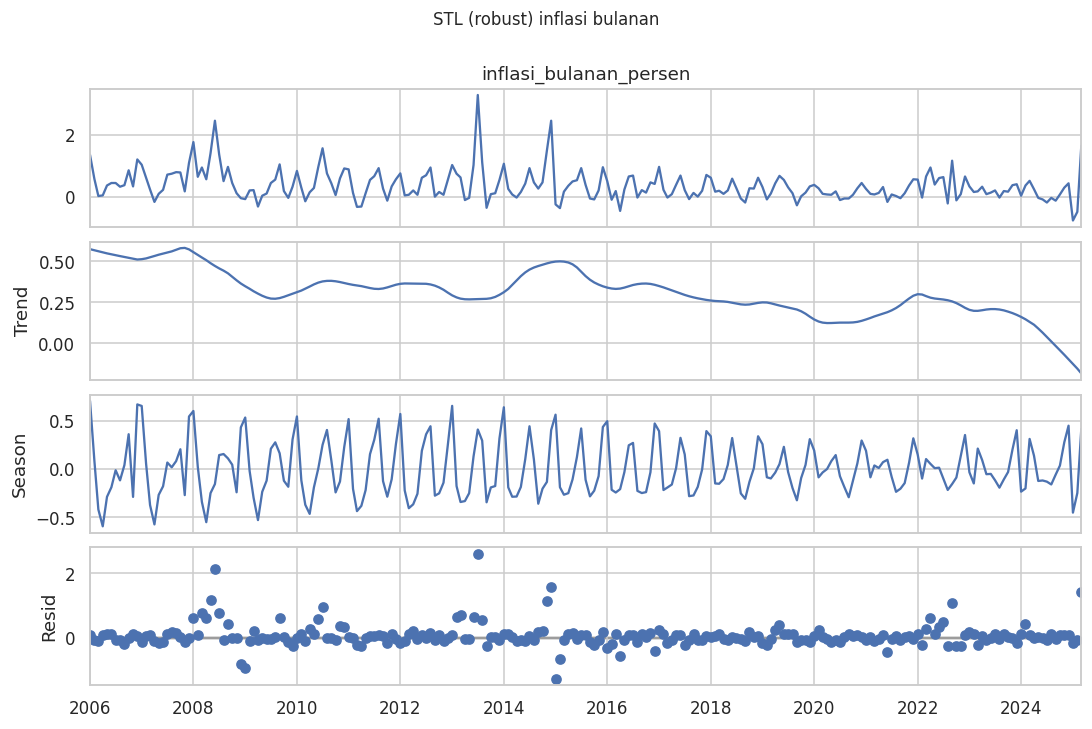

            F_tren  F_musiman
STL robust   0.140      0.357
STL biasa    0.381      0.585

komponen musiman STL rata-rata per bulan (persen poin):
           Jan    Feb    Mar    Apr    Mei    Jun    Jul    Agu    Sep    Okt  \
musiman  0.362 -0.125 -0.159 -0.239 -0.116  0.066  0.132  0.001 -0.152 -0.101   

           Nov    Des  
musiman -0.053  0.375  

tren STL awal / akhir      : 0.574 / -0.183
tren STL tertinggi / terendah : 0.582 Nov 2007 / -0.183 Mar 2025
rata-rata tren 2006-2012 vs 2016-2024 : 0.415 vs 0.218
rentang komponen musiman STL awal vs akhir data: 1.297 vs 0.898
std residu STL robust : 0.376
residu terbesar (mutlak): {'Jul 2013': 2.61, 'Jun 2008': 2.14, 'Dec 2014': 1.56, 'Mar 2025': 1.42}
korelasi musiman klasik vs STL : 0.639


In [ ]:
stl_rob = STL(inflasi, period=12, robust=True).fit()
stl_std = STL(inflasi, period=12, robust=False).fit()
fig = stl_rob.plot(); fig.set_size_inches(10, 6.5); fig.suptitle('STL (robust) inflasi bulanan', y=1.01)
plt.tight_layout(); plt.show()

kek = pd.DataFrame({'STL robust': kekuatan(stl_rob), 'STL biasa': kekuatan(stl_std)}).T.round(3)
print(kek)

mus_bulan = stl_rob.seasonal.groupby(stl_rob.seasonal.index.month).mean()
mus_bulan.index = nama_pendek
print('\nkomponen musiman STL rata-rata per bulan (persen poin):')
print(mus_bulan.round(3).to_frame('musiman').T)
print('\ntren STL awal / akhir      :', round(stl_rob.trend.iloc[0], 3), '/', round(stl_rob.trend.iloc[-1], 3))
print('tren STL tertinggi / terendah :', round(stl_rob.trend.max(), 3), stl_rob.trend.idxmax().strftime('%b %Y'), '/', round(stl_rob.trend.min(), 3), stl_rob.trend.idxmin().strftime('%b %Y'))
print('rata-rata tren 2006-2012 vs 2016-2024 :', round(stl_rob.trend['2006':'2012'].mean(), 3), 'vs', round(stl_rob.trend['2016':'2024'].mean(), 3))
print('rentang komponen musiman STL awal vs akhir data:', round(stl_rob.seasonal.iloc[:12].max() - stl_rob.seasonal.iloc[:12].min(), 3), 'vs', round(stl_rob.seasonal.iloc[-12:].max() - stl_rob.seasonal.iloc[-12:].min(), 3))
print('std residu STL robust :', round(stl_rob.resid.std(), 3))
print('residu terbesar (mutlak):', {k.strftime('%b %Y'): round(v, 2) for k, v in stl_rob.resid.abs().nlargest(4).items()})
print('korelasi musiman klasik vs STL :', round(np.corrcoef(adi.musiman.values, stl_rob.seasonal.values)[0, 1], 3))

### Jawaban Latihan 3.1 — kekuatan dan tafsir komponen

| Ukuran | STL robust | STL biasa |
|---|---|---|
| F_T (kekuatan tren) | **0,140** | 0,381 |
| F_S (kekuatan musiman) | **0,357** | 0,585 |

> **Interpretasi tiap komponen.**
> - **Tren:** F_T = 0,140 tergolong lemah. Level tren turun dari 0,574% di awal data, mencapai puncak 0,582% pada November 2007, lalu turun sampai −0,183% pada Maret 2025. Rata-rata tren 2006–2012 sebesar 0,415% dan 2016–2024 sebesar 0,218%. Nilai di ujung akhir (−0,183%) sebagian dipengaruhi deflasi Januari–Februari 2025, dan ujung data memang kurang stabil pada STL, jadi jangan dibaca terlalu harfiah.
> - **Musiman:** F_S = 0,357 sedang-lemah. Bulan dengan komponen tertinggi di STL adalah Desember (+0,375) dan Januari (+0,362), lalu Juli (+0,132); terendah April (−0,239). Rentang komponen musiman menyusut dari 1,297 (tahun pertama) menjadi 0,898 (tahun terakhir), sekitar sepertiganya, hal yang tidak bisa ditangkap dekomposisi klasik. Korelasi musiman klasik dan STL hanya 0,639, bukti pola musiman tidak tetap dan lemah.
> - **Residu:** simpangan baku 0,376, hampir sama besar dengan seluruh sisa musiman. Residu terbesar adalah Juli 2013 (2,61), Juni 2008 (2,14), Desember 2014 (1,56), dan Maret 2025 (1,42).
>
> **Mengapa angka robust lebih kecil daripada STL biasa?** Dengan `robust=True`, lonjakan dibiarkan di residu sehingga ragam residu besar dan F_T serta F_S turun. Pada STL biasa, lonjakan itu "bocor" ke tren dan musiman sehingga kekuatannya tampak lebih besar. Jadi angka robust lebih jujur untuk data berlonjakan seperti inflasi. Kesimpulannya: inflasi bulanan didominasi derau dan kejutan, dengan musiman ringan dan tren yang lemah.


## 3. Latihan 3.2 — Dekomposisi suhu Melbourne: klasik (m = 365) vs STL

jumlah hari            : 3652 ( 10.01 tahun )
titik tren hilang      : 364 hari = 10.0% dari data (klasik) | STL: 0
observasi per posisi   : 10 sampai 11 (dasar rata-rata tiap indeks musiman klasik)
baris asli di berkas  : 3650 | tanggal terisi interpolasi: 2
29 Februari ada pada tahun : [1984, 1988]
                                                         klasik m=365     STL
std residu                                                      2.543   2.536
autokorelasi residu lag 1                                       0.496   0.466
kekasaran musiman (rata-rata |selisih harian|, tahun 1)         0.744   1.538
rentang musiman tahun pertama                                  11.981  19.834
rentang musiman tahun terakhir                                 11.981  15.114

F_T dan F_S (STL): {'F_tren': np.float64(0.039), 'F_musiman': np.float64(0.605)}
korelasi pola musiman tahun pertama, klasik vs STL: 0.874


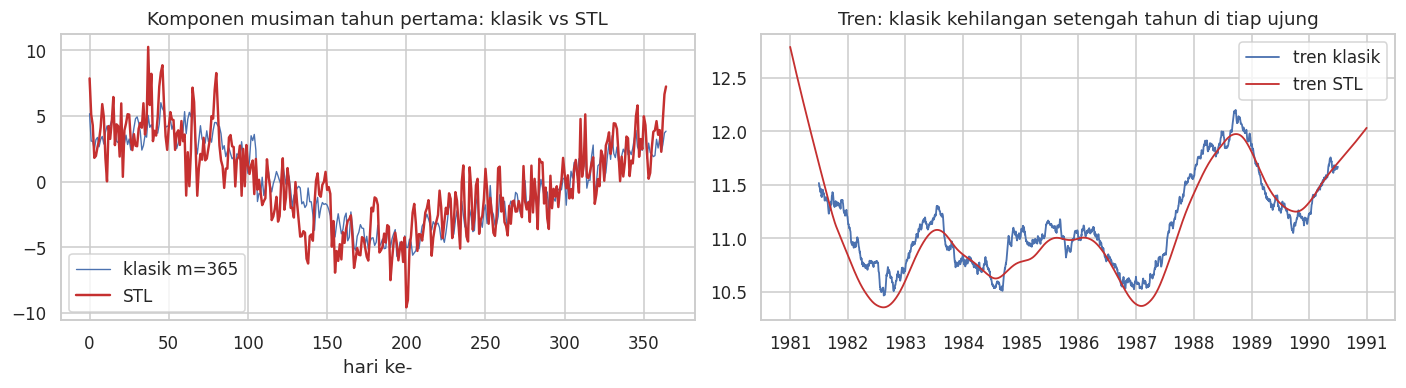

In [ ]:
kl_suhu = dekomposisi_klasik(suhu, m=365, model='additive')
stl_suhu = STL(suhu, period=365, robust=True, seasonal=31).fit()

n_per_posisi = pd.Series(np.arange(len(suhu)) % 365).value_counts()
print('jumlah hari            :', len(suhu), '(', round(len(suhu) / 365, 2), 'tahun )')
print('titik tren hilang      :', int(kl_suhu.tren.isna().sum()), 'hari =', f'{kl_suhu.tren.isna().mean():.1%}', 'dari data (klasik) | STL:', int(stl_suhu.trend.isna().sum()))
print('observasi per posisi   :', n_per_posisi.min(), 'sampai', n_per_posisi.max(), '(dasar rata-rata tiap indeks musiman klasik)')
print('baris asli di berkas  :', len(suhu_mentah), '| tanggal terisi interpolasi:', len(suhu) - len(suhu_mentah))
print('29 Februari ada pada tahun :', sorted(set(suhu.index[(suhu.index.month == 2) & (suhu.index.day == 29)].year)))

kasar = lambda s: s.diff().abs().mean()
tbl = pd.DataFrame({
    'klasik m=365': {'std residu': kl_suhu.residu.std(), 'autokorelasi residu lag 1': kl_suhu.residu.autocorr(1),
                     'kekasaran musiman (rata-rata |selisih harian|, tahun 1)': kasar(kl_suhu.musiman.iloc[:365]),
                     'rentang musiman tahun pertama': kl_suhu.musiman.iloc[:365].max() - kl_suhu.musiman.iloc[:365].min(),
                     'rentang musiman tahun terakhir': kl_suhu.musiman.iloc[-365:].max() - kl_suhu.musiman.iloc[-365:].min()},
    'STL': {'std residu': stl_suhu.resid.std(), 'autokorelasi residu lag 1': stl_suhu.resid.autocorr(1),
            'kekasaran musiman (rata-rata |selisih harian|, tahun 1)': kasar(stl_suhu.seasonal.iloc[:365]),
            'rentang musiman tahun pertama': stl_suhu.seasonal.iloc[:365].max() - stl_suhu.seasonal.iloc[:365].min(),
            'rentang musiman tahun terakhir': stl_suhu.seasonal.iloc[-365:].max() - stl_suhu.seasonal.iloc[-365:].min()}}).round(3)
pd.set_option('display.max_colwidth', 80)
print(tbl)
print('\nF_T dan F_S (STL):', {k: round(v, 3) for k, v in kekuatan(stl_suhu).items()})
print('korelasi pola musiman tahun pertama, klasik vs STL:', round(np.corrcoef(kl_suhu.musiman.iloc[:365], stl_suhu.seasonal.iloc[:365])[0, 1], 3))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(kl_suhu.musiman.iloc[:365].values, lw=.9, label='klasik m=365')
ax[0].plot(stl_suhu.seasonal.iloc[:365].values, lw=1.6, color='#c53030', label='STL')
ax[0].legend(); ax[0].set_title('Komponen musiman tahun pertama: klasik vs STL'); ax[0].set_xlabel('hari ke-')
ax[1].plot(kl_suhu.tren, lw=1.2, label='tren klasik'); ax[1].plot(stl_suhu.trend, lw=1.2, color='#c53030', label='tren STL')
ax[1].legend(); ax[1].set_title('Tren: klasik kehilangan setengah tahun di tiap ujung')
plt.tight_layout(); plt.show()

### Jawaban Latihan 3.2

| Ukuran | Klasik (m = 365) | STL |
|---|---|---|
| Titik tren hilang | 364 hari (10,0%) | 0 |
| Simpangan baku residu | 2,543 | 2,536 |
| Autokorelasi residu lag 1 | 0,496 | 0,466 |
| Rentang musiman tahun pertama | 11,98 | 19,83 |
| Rentang musiman tahun terakhir | 11,98 (tetap) | 15,11 |
| Kekasaran musiman (rata-rata selisih harian) | 0,744 | 1,538 |

F_T (STL) = 0,039 dan F_S (STL) = 0,605. Korelasi pola musiman tahun pertama antara klasik dan STL 0,874.

> **Mengapa periode 365 pada data harian kurang memuaskan untuk dekomposisi klasik?**
> 1. **Tahun kabisat dan panjang tahun 365,25 hari.** Dekomposisi klasik menganggap tahun tepat 365 hari. Di data ini 29 Februari ada pada 1984 dan 1988 (berkas aslinya hanya 3.650 baris, sehingga 2 tanggal diisi interpolasi). Setelah setiap tahun kabisat, posisi ke-*k* dalam siklus bergeser satu hari terhadap tanggal kalender, jadi di ujung data pergeserannya bisa mencapai dua hari. Rata-rata per posisi akhirnya mencampur tanggal yang berbeda.
> 2. **Data terlalu pendek.** Hanya ±10 tahun, sehingga tiap indeks musiman harian dihitung dari 10–11 pengamatan saja, sementara derau cuaca besar (simpangan baku residu 2,5 °C). Hasilnya tidak mulus.
> 3. **Kehilangan data tren.** Rata-rata bergerak terpusat 365 hari menghapus 182 hari di tiap ujung, total 364 hari atau 10% data. STL punya tren di seluruh rentang.
> 4. **Pola dipaksa sama tiap tahun.** Rentang musiman klasik selalu 11,98 °C, sedangkan STL membiarkannya berubah (19,83 menjadi 15,11).
>
> **Perbandingan dengan STL.** Dari sisi kecocokan, keduanya hampir sama (simpangan baku residu 2,543 vs 2,536). STL unggul karena tren penuh dan pola musiman yang boleh berubah. Tetapi di data ini komponen musiman STL justru lebih bergerigi (0,744 vs 1,538), karena jendela penghalus musiman 31 hanya menghadapi sekitar 10 siklus per hari, sehingga hampir tidak ada perataan. Rentang tahun pertama 19,83 °C juga tampak terlalu besar dibanding rata-rata bulanan (selisih 8,7 °C), tanda efek ujung data. Jadi kedua metode punya kelemahan pada data harian sependek ini.
>
> Nilai F_T 0,039 menegaskan **tidak ada tren** pada suhu Melbourne, sedangkan F_S 0,605 menunjukkan musiman yang kuat tetapi masih dikalahkan residu cuaca harian yang besar.


## 4. Latihan 3.3 — Kesalahan periode pada Airline (period = 6, 12, 24)

             std residu  autokorelasi residu lag 12  \
period = 6        0.055                       0.838   
period = 12       0.033                       0.337   
period = 24       0.034                       0.343   

             autokorelasi residu lag 6  rentang indeks musiman  \
period = 6                      -0.743                   0.179   
period = 12                     -0.247                   0.425   
period = 24                     -0.248                   0.455   

             titik tren hilang  
period = 6                 6.0  
period = 12               12.0  
period = 24               24.0  


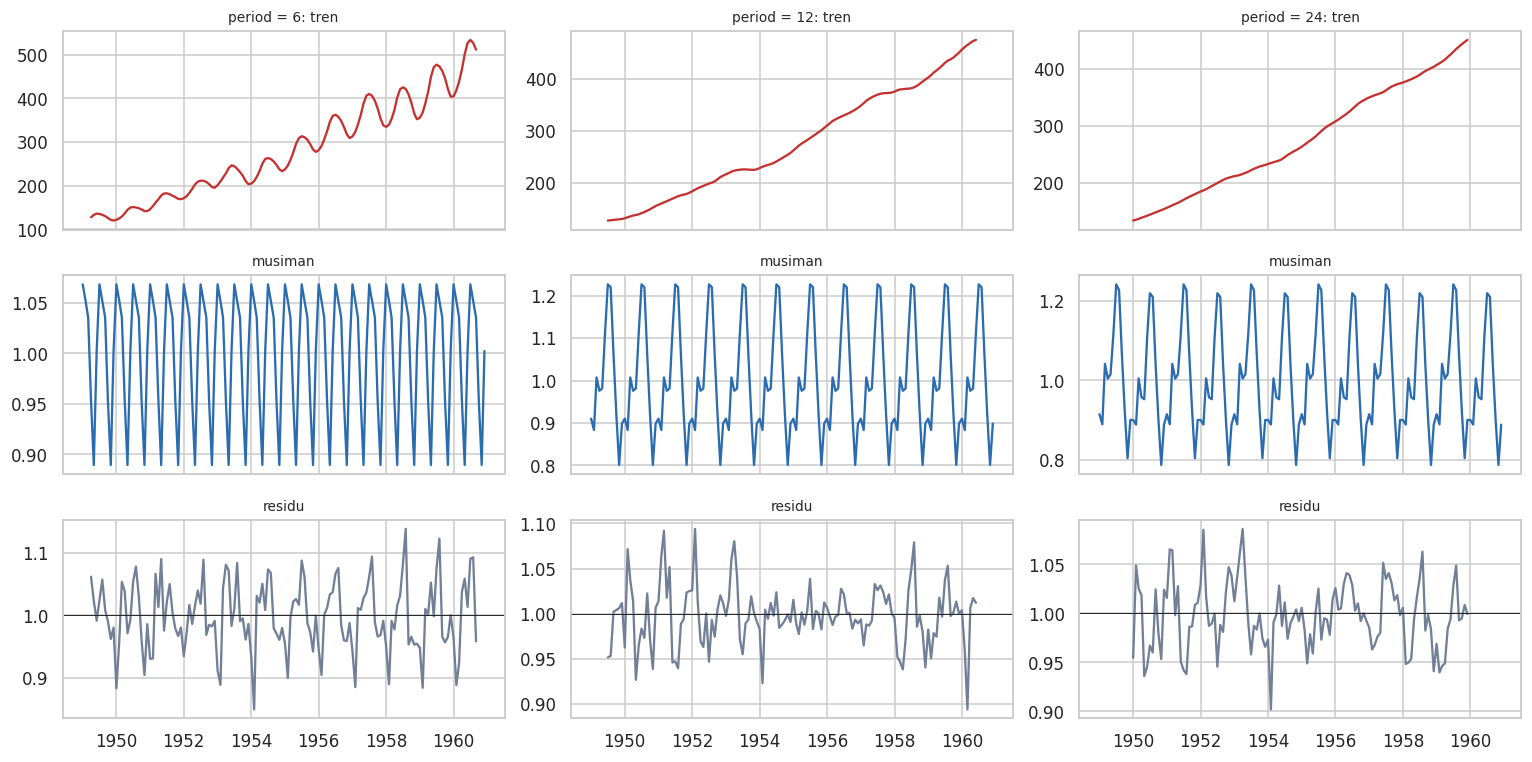

indeks musiman period=6 (satu siklus)  : [1.068, 1.052, 1.035, 0.953, 0.889, 1.002]
indeks musiman period=12 (satu siklus) : [0.91, 0.884, 1.007, 0.976, 0.981, 1.113, 1.227, 1.22, 1.06, 0.922, 0.801, 0.899]
period=24: korelasi paruh 1 vs paruh 2 indeks musiman: 0.992


In [ ]:
hasil = {}
dekom = {}
for m in [6, 12, 24]:
    d = seasonal_decompose(air, model='multiplicative', period=m)
    dekom[m] = d
    r = d.resid.dropna()
    hasil[f'period = {m}'] = {
        'std residu': r.std(),
        'autokorelasi residu lag 12': d.resid.autocorr(12),
        'autokorelasi residu lag 6': d.resid.autocorr(6),
        'rentang indeks musiman': d.seasonal.max() - d.seasonal.min(),
        'titik tren hilang': int(d.trend.isna().sum()),
    }
tabel_m = pd.DataFrame(hasil).T.round(3)
print(tabel_m)

fig, axs = plt.subplots(3, 3, figsize=(14, 7), sharex=True)
for j, m in enumerate([6, 12, 24]):
    d = dekom[m]
    axs[0, j].plot(d.trend, color='#c53030'); axs[0, j].set_title(f'period = {m}: tren', fontsize=9)
    axs[1, j].plot(d.seasonal, color='#2b6cb0'); axs[1, j].set_title('musiman', fontsize=9)
    axs[2, j].plot(d.resid, color='#718096'); axs[2, j].axhline(1, color='k', lw=.6); axs[2, j].set_title('residu', fontsize=9)
plt.tight_layout(); plt.show()

print('indeks musiman period=6 (satu siklus)  :', dekom[6].seasonal.iloc[:6].round(3).tolist())
print('indeks musiman period=12 (satu siklus) :', dekom[12].seasonal.iloc[:12].round(3).tolist())
print('period=24: korelasi paruh 1 vs paruh 2 indeks musiman:', round(np.corrcoef(dekom[24].seasonal.iloc[:12], dekom[24].seasonal.iloc[12:24])[0, 1], 3))

### Jawaban Latihan 3.3

| Ukuran (Airline, multiplikatif) | period = 6 | period = 12 | period = 24 |
|---|---|---|---|
| Simpangan baku residu | 0,055 | **0,033** | 0,034 |
| Autokorelasi residu lag 12 | **0,838** | 0,337 | 0,343 |
| Autokorelasi residu lag 6 | **−0,743** | −0,247 | −0,248 |
| Rentang indeks musiman | 0,179 | 0,425 | 0,455 |
| Titik tren hilang | 6 | 12 | 24 |

> **Interpretasi.**
> - **period = 6 (salah):** periode asli 12 bulan, jadi siklus tahunan tidak tertangkap penuh. Indeks musiman hanya berkisar 0,889–1,068 (rentang 0,179, kurang dari separuh nilai yang benar 0,425). Sisa pola tahunan menumpuk di residu: autokorelasi residu lag 12 melonjak ke 0,838 dan lag 6 ke −0,743, sedangkan simpangan baku residu naik dari 0,033 menjadi 0,055 (sekitar 67% lebih besar). Residu yang baik seharusnya mirip derau, ini tidak.
> - **period = 24 (kelipatan 12):** hasilnya hampir sama dengan period = 12 (simpangan baku residu 0,034, rentang musiman 0,455). Dua paruh indeks musimannya hampir identik (korelasi 0,992) karena pola 12 bulan memang berulang dua kali dalam 24 bulan. Harganya: 24 titik tren hilang, dan tiap indeks hanya dirata-rata dari 6 siklus sehingga estimasinya lebih berisik.
>
> **Pelajaran:** periode yang bukan kelipatan periode sebenarnya merusak dekomposisi, sedangkan kelipatannya masih berfungsi tetapi boros data. Periode harus ditentukan dari konteks dan data (frekuensi, seasonal plot, ACF), bukan ditebak.


## Kesimpulan

1. Data Tugas 1 (inflasi bulanan) harus didekomposisi **aditif** karena 42 dari 231 nilainya ≤ 0. Residu aditif tidak menyisakan musiman (autokorelasi lag 12 = 0,115), tetapi variabilitasnya mengecil seiring waktu (rasio 0,57).
2. Kekuatan komponen inflasi rendah: F_T = 0,140 dan F_S = 0,357 (STL robust). Level tren turun dari sekitar 0,42% (2006–2012) ke 0,22% (2016–2024), musiman ringan dengan Desember, Januari, dan Juli tertinggi, serta April terendah. Residu dan lonjakan harga mendominasi.
3. STL robust lebih jujur daripada STL biasa untuk data berlonjak, karena lonjakan tetap tinggal di residu. Pada STL biasa F_T dan F_S terlihat lebih besar (0,381 dan 0,585) akibat lonjakan yang bocor ke komponen lain.
4. Dekomposisi klasik dengan m = 365 pada data harian kurang memuaskan: efek tahun kabisat, hanya ±10 tahun data, dan 10% data tren hilang. STL lebih fleksibel, tetapi pada data sependek ini juga punya efek ujung.
5. Periode yang salah (6 untuk data dengan periode 12) merusak dekomposisi: residu masih membawa pola tahunan (autokorelasi lag 12 = 0,838). Periode kelipatan (24) masih berfungsi tetapi kurang efisien.
